link: https://www.kaggle.com/datasets/issamjebnouni/carddData

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/

In [ ]:
!kaggle datasets download -d issamjebnouni/cardd

Dataset URL: https://www.kaggle.com/datasets/issamjebnouni/cardd
License(s): unknown
100% 2.81G/2.81G [02:43<00:00, 18.4MB/s]



In [ ]:
!unzip /content/cardd.zip

Archive:  /content/cardd.zip
  inflating: image_info.xlsx         
  inflating: test.json               
  inflating: test/000012.jpg         
  inflating: test/000015.jpg         
  inflating: test/000023.jpg         
  inflating: test/000033.jpg         
  inflating: test/000040.jpg         
  inflating: test/000042.jpg         
  inflating: test/000044.jpg         
  inflating: test/000057.jpg         
  inflating: test/000082.jpg         
  inflating: test/000088.jpg         
  inflating: test/000090.jpg         
  inflating: test/000106.jpg         
  inflating: test/000128.jpg         
  inflating: test/000152.jpg         
  inflating: test/000165.jpg         
  inflating: test/000175.jpg         
  inflating: test/000185.jpg         
  inflating: test/000191.jpg         
  inflating: test/000204.jpg         
  inflating: test/000214.jpg         
  inflating: test/000224.jpg         
  inflating: test/000233.jpg         
  inflating: test/000237.jpg         
  inflating: test/000

# Préparation du Dataset Multi-Classes

In [ ]:
import os
import json
import shutil
from collections import Counter

BASE_DIR   = '/content'
OUTPUT_DIR = '/content/cardd_multiclass'

CATEGORY_NAMES = {
    1: 'dent',
    2: 'scratch',
    3: 'crack',
    4: 'glass_shatter',
    5: 'lamp_broken',
    6: 'tire_flat'
}

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

for split in ['train', 'val']:
    with open(f'{BASE_DIR}/{split}.json', 'r') as f:
        data = json.load(f)

    id_to_filename = {img['id']: img['file_name'] for img in data['images']}

    image_to_categories = {}
    for ann in data['annotations']:
        img_id = ann['image_id']
        cat_id = ann['category_id']
        image_to_categories.setdefault(img_id, []).append(cat_id)

    image_to_label = {}
    for img_id, cat_list in image_to_categories.items():
        dominant = Counter(cat_list).most_common(1)[0][0]
        image_to_label[img_id] = CATEGORY_NAMES[dominant]

    for cls_name in CATEGORY_NAMES.values():
        os.makedirs(f'{OUTPUT_DIR}/{split}/{cls_name}', exist_ok=True)

    class_counts = Counter()
    for img_id, label in image_to_label.items():
        fname = id_to_filename[img_id]
        src   = f'{BASE_DIR}/{split}/{fname}'
        dst   = f'{OUTPUT_DIR}/{split}/{label}/{fname}'
        if os.path.exists(src):
            shutil.copy(src, dst)
            class_counts[label] += 1

    print(f"\n[{split}] Distribution:")
    for cls, cnt in sorted(class_counts.items(), key=lambda x: -x[1]):
        print(f"   {cls:<15}: {cnt}")
    print(f"   {'TOTAL':<15}: {sum(class_counts.values())}")


[train] Distribution:
   scratch        : 1074
   dent           : 967
   glass_shatter  : 391
   tire_flat      : 173
   crack          : 141
   lamp_broken    : 70
   TOTAL          : 2816

[val] Distribution:
   scratch        : 308
   dent           : 277
   glass_shatter  : 110
   crack          : 46
   tire_flat      : 44
   lamp_broken    : 25
   TOTAL          : 810


# Data Loader

crack - 0

dent - 1

glass_shatter -2

lamp_broken - 3

scratch -4

tire_flat -5


# Configuration

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
NUM_CLASSES = 6

train_path = '/content/cardd_multiclass/train'
valid_path = '/content/cardd_multiclass/val'

# Data Augmentation

In [ ]:
# ============================================================
# VERSION AVEC DATA AUGMENTATION (basée sur data_augmentation.md)
# ============================================================
# Techniques retenues :
# ✅ Horizontal flip (texture isotrope)
# ✅ Rotation légère (±15°)
# ✅ Zoom léger (±10%)
# ✅ Luminosité via shear_range (proxy)
# ✅ Translation via width/height_shift
# ❌ Flip vertical (physiquement irréaliste)
# ❌ Flou (détruit la texture)

train_datagen_augmented = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,           # ±15° (texture isotrope)
    width_shift_range=0.1,       # Translation horizontale ±10%
    height_shift_range=0.1,      # Translation verticale ±10%
    shear_range=0.1,             # Cisaillement léger
    zoom_range=0.1,              # Zoom ±10%
    horizontal_flip=True,        # Flip horizontal (retenu)
    brightness_range=[0.85, 1.15], # Luminosité ±15%
    fill_mode='reflect'          # Remplissage par réflexion
)

# Validation : PAS d'augmentation, uniquement normalisation
valid_datagen = ImageDataGenerator(rescale=1./255)

# ============================================================
# VERSION SANS DATA AUGMENTATION (pour comparaison)
# ============================================================
train_datagen_no_aug = ImageDataGenerator(rescale=1./255)

print("✅ Data generators configurés")

✅ Data generators configurés


# Lets define our custom architecture

In [ ]:
def build_model():
    """Architecture custom optimisée pour classification 6 classes."""
    model = Sequential()

    model.add(Input(shape=(224, 224, 3)))

    # Bloc 1
    model.add(Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

    # Bloc 2
    model.add(Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

    # Bloc 3
    model.add(Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size=(2, 2), strides=2))

    # Global Average Pooling
    model.add(GlobalAveragePooling2D())

    # Classification
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(NUM_CLASSES, activation='softmax'))

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("✅ Fonction build_model() définie")

✅ Fonction build_model() définie


In [ ]:
model = build_model()
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,710 (502.77 KB)

 Trainable params: 128,262 (501.02 KB)

 Non-trainable params: 448 (1.75 KB)

# Callbacks pour Éviter l'Overfitting

In [ ]:
EPOCHS = 30  # Même nombre pour les deux modèles

# Callbacks SANS early stopping (pour comparaison équitable)
callbacks_fair = [
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

# Entraînement SANS Data Augmentation (Baseline)

In [ ]:
# ============================================================
# MODÈLE 1 — SANS AUGMENTATION
# ============================================================
print("=" * 70)
print("MODÈLE 1 — SANS DATA AUGMENTATION (30 epochs)")
print("=" * 70)

train_set_no_aug = train_datagen_no_aug.flow_from_directory(
    train_path, target_size=(224, 224), batch_size=32, class_mode='sparse'
)
valid_set = valid_datagen.flow_from_directory(
    valid_path, target_size=(224, 224), batch_size=32, class_mode='sparse'
)

model_no_aug = build_model()
history_no_aug = model_no_aug.fit(
    train_set_no_aug,
    validation_data=valid_set,
    epochs=EPOCHS,
    callbacks=callbacks_fair,
    verbose=1
)

print("\n✅ Entraînement SANS augmentation terminé")

MODÈLE 1 — SANS DATA AUGMENTATION (30 epochs)
Found 2816 images belonging to 6 classes.
Found 810 images belonging to 6 classes.
Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 65s 671ms/step - accuracy: 0.3892 - loss: 1.4318 - val_accuracy: 0.3741 - val_loss: 1.6111 - learning_rate: 1.0000e-04
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 55s 631ms/step - accuracy: 0.4460 - loss: 1.2622 - val_accuracy: 0.3840 - val_loss: 1.4782 - learning_rate: 1.0000e-04
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 55s 626ms/step - accuracy: 0.4759 - loss: 1.2159 - val_accuracy: 0.3840 - val_loss: 1.4411 - learning_rate: 1.0000e-04
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 55s 625ms/step - accuracy: 0.4663 - loss: 1.2004 - val_accuracy: 0.3753 - val_loss: 1.4220 - learning_rate: 1.0000e-04
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 56s 637ms/step - accuracy: 0.4883 - loss: 1.1696 - val_accuracy: 0.4099 - val_loss: 1.3484 - learning_rate: 1.0000e-04
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 55s 620ms/step - accuracy: 0.4975 - loss: 1.1460

# Entraînement AVEC Data Augmentation

In [ ]:
# ============================================================
# MODÈLE 2 — AVEC AUGMENTATION (même nombre d'epochs)
# ============================================================
print("=" * 70)
print("MODÈLE 2 — AVEC DATA AUGMENTATION (30 epochs)")
print("=" * 70)

train_set_aug = train_datagen_augmented.flow_from_directory(
    train_path, target_size=(224, 224), batch_size=32, class_mode='sparse'
)
valid_set_2 = valid_datagen.flow_from_directory(
    valid_path, target_size=(224, 224), batch_size=32, class_mode='sparse'
)

model_aug = build_model()
history_aug = model_aug.fit(
    train_set_aug,
    validation_data=valid_set_2,
    epochs=EPOCHS,
    callbacks=callbacks_fair,
    verbose=1
)

print("\n✅ Entraînement AVEC augmentation terminé")

MODÈLE 2 — AVEC DATA AUGMENTATION (30 epochs)
Found 2816 images belonging to 6 classes.
Found 810 images belonging to 6 classes.
Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.3853 - loss: 1.4288 - val_accuracy: 0.3704 - val_loss: 1.5988 - learning_rate: 1.0000e-04
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 88s 998ms/step - accuracy: 0.4592 - loss: 1.2806 - val_accuracy: 0.3617 - val_loss: 1.4585 - learning_rate: 1.0000e-04
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 86s 982ms/step - accuracy: 0.4592 - loss: 1.2432 - val_accuracy: 0.3765 - val_loss: 1.4263 - learning_rate: 1.0000e-04
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 88s 995ms/step - accuracy: 0.4553 - loss: 1.2216 - val_accuracy: 0.3790 - val_loss: 1.3953 - learning_rate: 1.0000e-04
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.4669 - loss: 1.1996
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
88/88 ━━━━━━━━━━━━━━━━━━━━ 88s 1s/step - accuracy: 0.4773 - loss: 1.2001 - val_accur

# Comparaison Visuelle des Résultats

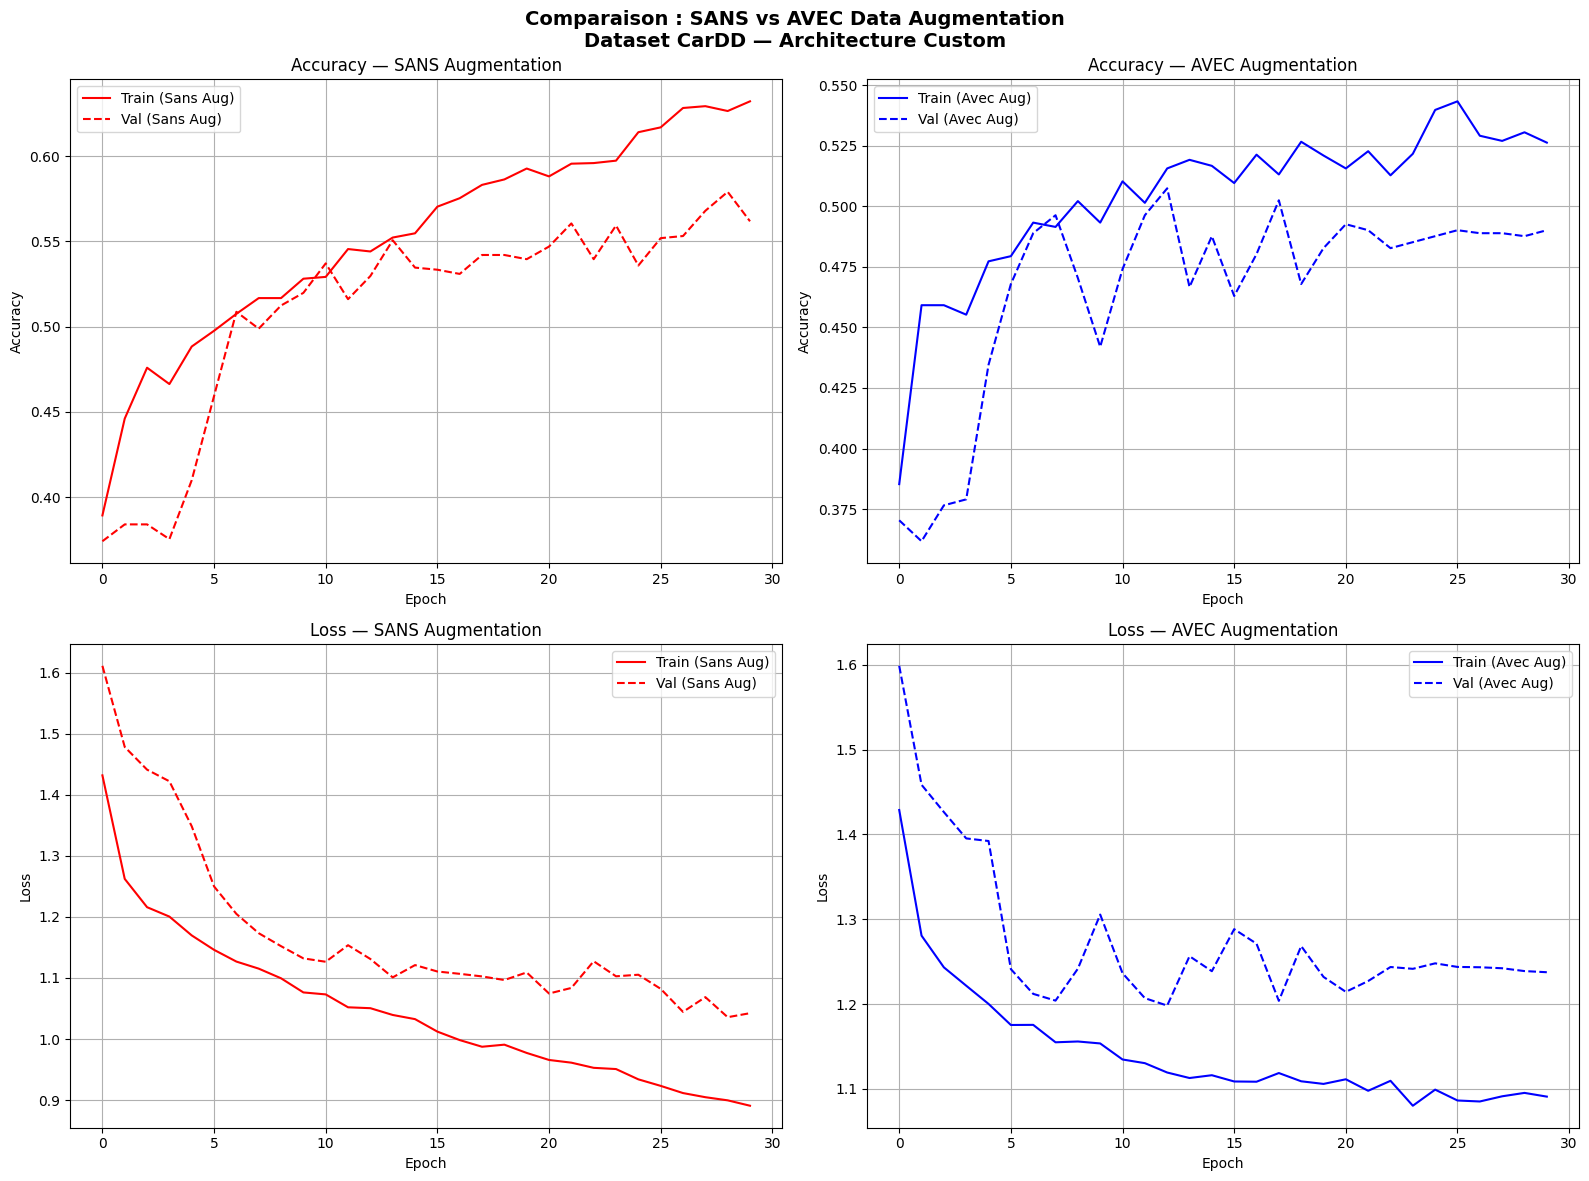

✅ Graphique de comparaison sauvegardé


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ---- Accuracy ----
axes[0, 0].plot(history_no_aug.history['accuracy'], 'r-', label='Train (Sans Aug)')
axes[0, 0].plot(history_no_aug.history['val_accuracy'], 'r--', label='Val (Sans Aug)')
axes[0, 0].set_title('Accuracy — SANS Augmentation', fontsize=12)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(history_aug.history['accuracy'], 'b-', label='Train (Avec Aug)')
axes[0, 1].plot(history_aug.history['val_accuracy'], 'b--', label='Val (Avec Aug)')
axes[0, 1].set_title('Accuracy — AVEC Augmentation', fontsize=12)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True)

# ---- Loss ----
axes[1, 0].plot(history_no_aug.history['loss'], 'r-', label='Train (Sans Aug)')
axes[1, 0].plot(history_no_aug.history['val_loss'], 'r--', label='Val (Sans Aug)')
axes[1, 0].set_title('Loss — SANS Augmentation', fontsize=12)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(history_aug.history['loss'], 'b-', label='Train (Avec Aug)')
axes[1, 1].plot(history_aug.history['val_loss'], 'b--', label='Val (Avec Aug)')
axes[1, 1].set_title('Loss — AVEC Augmentation', fontsize=12)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Loss')
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.suptitle('Comparaison : SANS vs AVEC Data Augmentation\nDataset CarDD — Architecture Custom',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('comparaison_data_augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Graphique de comparaison sauvegardé")

# Tableau Récapitulatif des Résultats

In [ ]:
# Récupérer les meilleures métriques
best_epoch_no_aug = np.argmax(history_no_aug.history['val_accuracy'])
best_epoch_aug = np.argmax(history_aug.history['val_accuracy'])

results = {
    'Sans Augmentation': {
        'Best Epoch': best_epoch_no_aug + 1,
        'Train Accuracy': history_no_aug.history['accuracy'][best_epoch_no_aug],
        'Val Accuracy': history_no_aug.history['val_accuracy'][best_epoch_no_aug],
        'Train Loss': history_no_aug.history['loss'][best_epoch_no_aug],
        'Val Loss': history_no_aug.history['val_loss'][best_epoch_no_aug],
        'Overfitting Gap': (history_no_aug.history['accuracy'][best_epoch_no_aug] -
                           history_no_aug.history['val_accuracy'][best_epoch_no_aug])
    },
    'Avec Augmentation': {
        'Best Epoch': best_epoch_aug + 1,
        'Train Accuracy': history_aug.history['accuracy'][best_epoch_aug],
        'Val Accuracy': history_aug.history['val_accuracy'][best_epoch_aug],
        'Train Loss': history_aug.history['loss'][best_epoch_aug],
        'Val Loss': history_aug.history['val_loss'][best_epoch_aug],
        'Overfitting Gap': (history_aug.history['accuracy'][best_epoch_aug] -
                           history_aug.history['val_accuracy'][best_epoch_aug])
    }
}

print("=" * 70)
print("📊 TABLEAU COMPARATIF — Impact de la Data Augmentation")
print("=" * 70)
print(f"\n{'Métrique':<25} {'Sans Augmentation':<20} {'Avec Augmentation':<20}")
print("-" * 65)

for metric in ['Best Epoch', 'Train Accuracy', 'Val Accuracy',
               'Train Loss', 'Val Loss', 'Overfitting Gap']:
    val1 = results['Sans Augmentation'][metric]
    val2 = results['Avec Augmentation'][metric]

    if isinstance(val1, float):
        print(f"{metric:<25} {val1:<20.4f} {val2:<20.4f}")
    else:
        print(f"{metric:<25} {val1:<20} {val2:<20}")

# Verdict
gap_no_aug = results['Sans Augmentation']['Overfitting Gap']
gap_aug = results['Avec Augmentation']['Overfitting Gap']

print("\n" + "=" * 70)
print("💡 VERDICT")
print("=" * 70)

if gap_aug < gap_no_aug:
    reduction = ((gap_no_aug - gap_aug) / gap_no_aug) * 100
    print(f"✅ La data augmentation RÉDUIT l'overfitting de {reduction:.1f}%")
    print(f"   Gap sans aug : {gap_no_aug:.4f}")
    print(f"   Gap avec aug : {gap_aug:.4f}")
else:
    print(f"⚠️  La data augmentation n'a pas réduit l'overfitting sur ce dataset")
    print(f"   Gap sans aug : {gap_no_aug:.4f}")
    print(f"   Gap avec aug : {gap_aug:.4f}")

val_acc_no_aug = results['Sans Augmentation']['Val Accuracy']
val_acc_aug = results['Avec Augmentation']['Val Accuracy']

if val_acc_aug > val_acc_no_aug:
    improvement = (val_acc_aug - val_acc_no_aug) * 100
    print(f"\n✅ La data augmentation AMÉLIORE la val accuracy de +{improvement:.1f} points")
else:
    decrease = (val_acc_no_aug - val_acc_aug) * 100
    print(f"\n⚠️  La data augmentation DIMINUE la val accuracy de -{decrease:.1f} points")

print("\n⚠️  Note : Ce test sur CarDD est un test TECHNIQUE du pipeline.")

📊 TABLEAU COMPARATIF — Impact de la Data Augmentation

Métrique                  Sans Augmentation    Avec Augmentation   
-----------------------------------------------------------------
Best Epoch                29                   13                  
Train Accuracy            0.6264               0.5156              
Val Accuracy              0.5790               0.5074              
Train Loss                0.8996               1.1192              
Val Loss                  1.0357               1.1981              
Overfitting Gap           0.0474               0.0082              

💡 VERDICT
✅ La data augmentation RÉDUIT l'overfitting de 82.7%
   Gap sans aug : 0.0474
   Gap avec aug : 0.0082

⚠️  La data augmentation DIMINUE la val accuracy de -7.2 points

⚠️  Note : Ce test sur CarDD est un test TECHNIQUE du pipeline.


# Visualisation des Images Augmentées





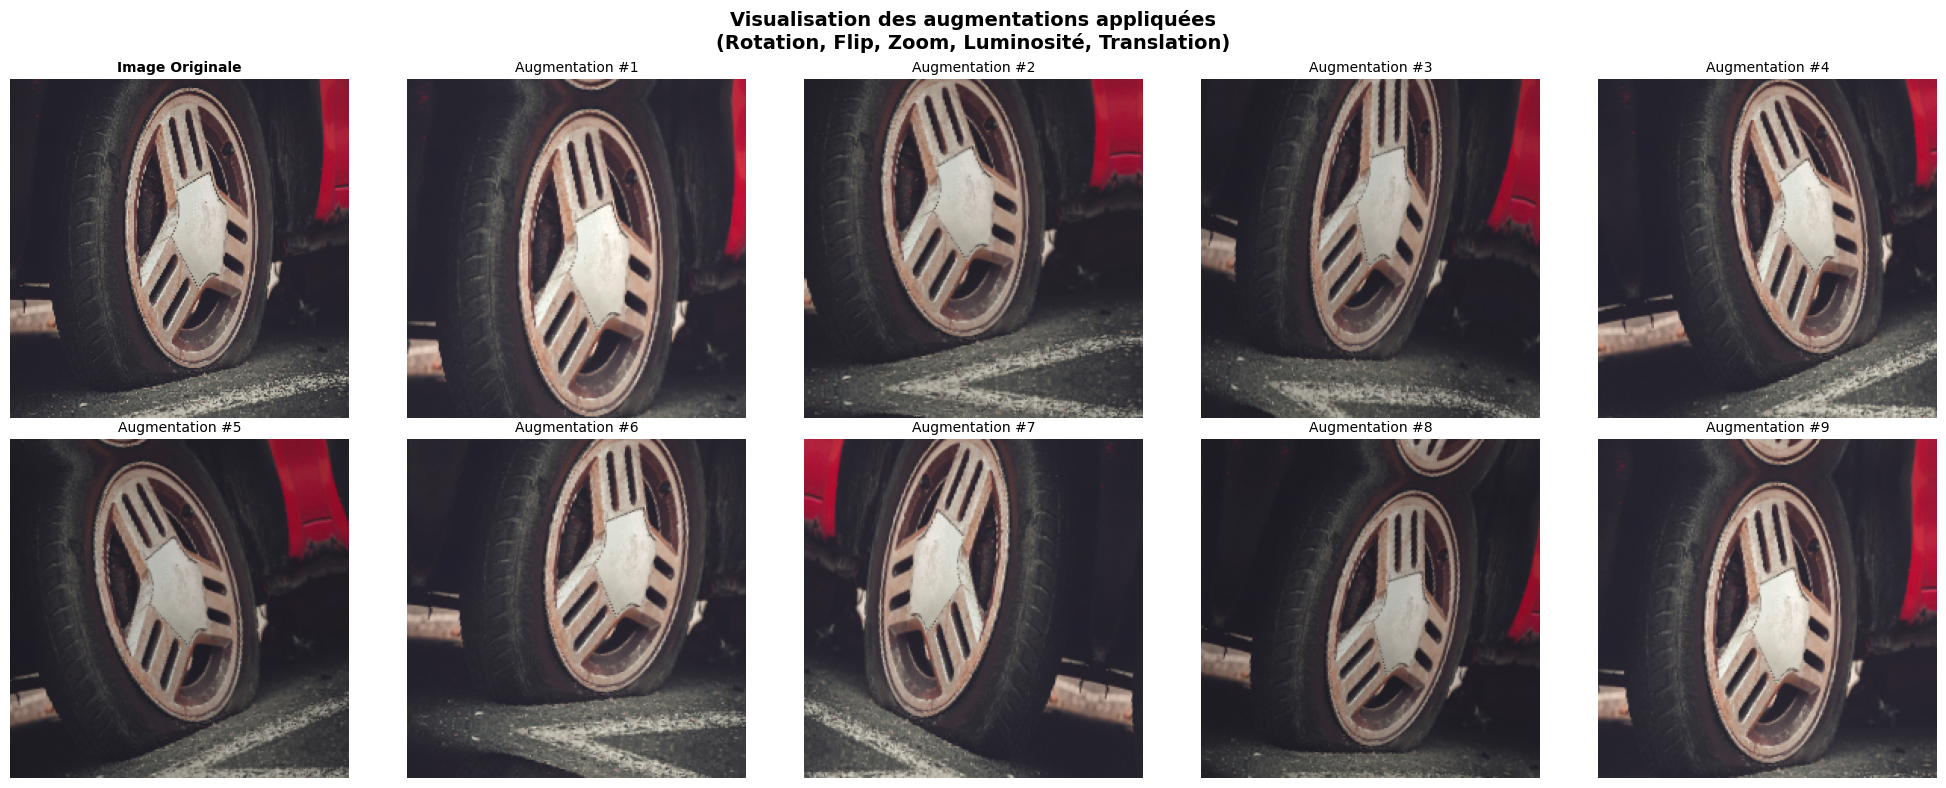

✅ Visualisation des augmentations sauvegardée


In [ ]:
# Visualiser l'effet de la data augmentation sur quelques images
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# Charger une image exemple
sample_dir = os.path.join(train_path, 'tire_flat')
sample_images = os.listdir(sample_dir)
sample_img_path = os.path.join(sample_dir, sample_images[0])

img = load_img(sample_img_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = img_array.reshape((1,) + img_array.shape)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

# Ligne 1 : Image originale + 4 augmentations
axes[0, 0].imshow(img)
axes[0, 0].set_title('Image Originale', fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

augmented_iter = train_datagen_augmented.flow(img_array, batch_size=1)
for i in range(1, 5):
    augmented_img = next(augmented_iter)[0]
    axes[0, i].imshow(augmented_img)
    axes[0, i].set_title(f'Augmentation #{i}', fontsize=10)
    axes[0, i].axis('off')

# Ligne 2 : 5 autres augmentations
for i in range(5):
    augmented_img = next(augmented_iter)[0]
    axes[1, i].imshow(augmented_img)
    axes[1, i].set_title(f'Augmentation #{i+5}', fontsize=10)
    axes[1, i].axis('off')

plt.suptitle('Visualisation des augmentations appliquées\n(Rotation, Flip, Zoom, Luminosité, Translation)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('visualisation_augmentations.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Visualisation des augmentations sauvegardée")

# Inférence (Test Final)

Classes : ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']


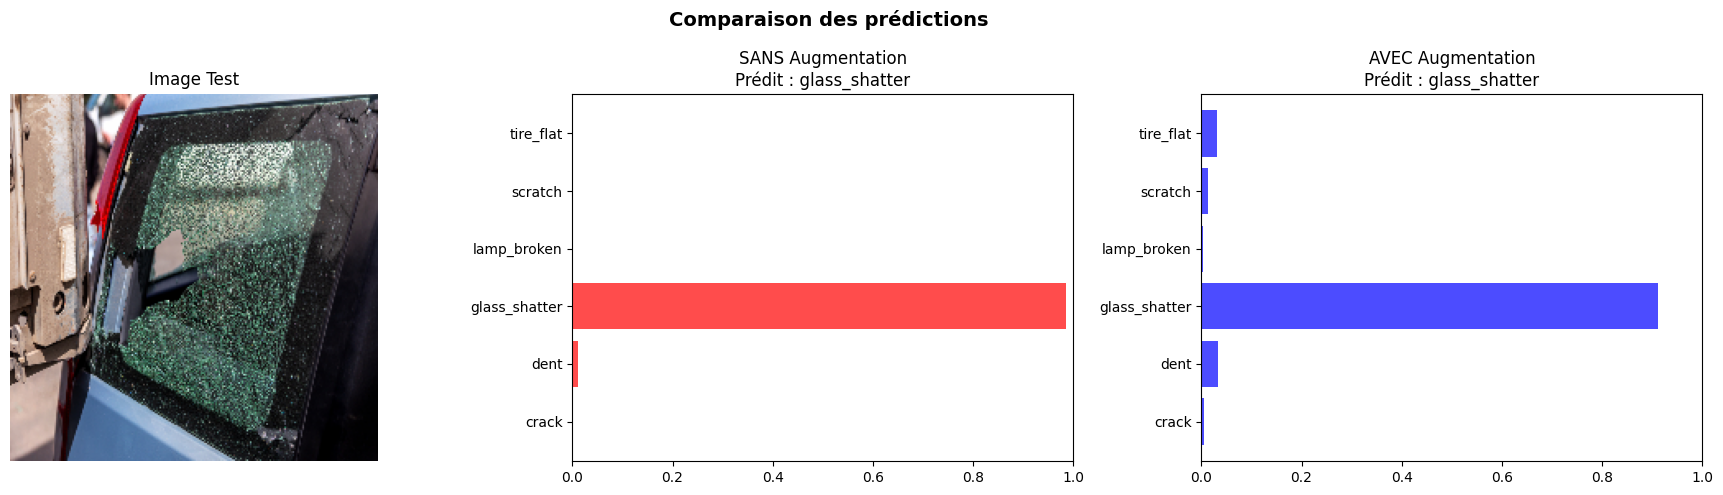

In [ ]:
import cv2

# Mapper les classes
class_names = list(train_set_aug.class_indices.keys())
print(f"Classes : {class_names}")

# Charger et prédire une image
test_img = cv2.imread("/content/test/000175.jpg")
test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
test_img_resized = cv2.resize(test_img, (224, 224))
test_input = test_img_resized.reshape((1, 224, 224, 3)) / 255.0

# Prédictions des deux modèles
pred_no_aug = model_no_aug.predict(test_input, verbose=0)
pred_aug = model_aug.predict(test_input, verbose=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Image
axes[0].imshow(test_img_resized)
axes[0].set_title('Image Test', fontsize=12)
axes[0].axis('off')

# Prédiction Sans Aug
axes[1].barh(class_names, pred_no_aug[0], color='red', alpha=0.7)
axes[1].set_title(f'SANS Augmentation\nPrédit : {class_names[np.argmax(pred_no_aug)]}', fontsize=12)
axes[1].set_xlim(0, 1)

# Prédiction Avec Aug
axes[2].barh(class_names, pred_aug[0], color='blue', alpha=0.7)
axes[2].set_title(f'AVEC Augmentation\nPrédit : {class_names[np.argmax(pred_aug)]}', fontsize=12)
axes[2].set_xlim(0, 1)

plt.suptitle('Comparaison des prédictions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('comparaison_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

## ways to reduce overfitting
- Add more data
- Data Augmentation
- Dropout
- Batch Norm
- Reduce complexity